# PROYEK KECERDASAN BISNIS: ANALISIS & PREDIKSI CUSTOMER CHURN
**Studi Kasus:** Industri Telekomunikasi (Customer Churn Analysis & Machine Learning Prediction)  
**Tujuan Analisis:**  
1. **Exploratory Data Analysis (EDA):** Mengidentifikasi pola dan faktor-faktor utama penyebab pelanggan berhenti berlangganan (*churn*).
2. **Model Machine Learning:** Membangun dan membandingkan 3 model klasifikasi (*Logistic Regression, Decision Tree, Random Forest*) dengan penanganan *imbalanced data*.
3. **Kecerdasan Bisnis & Tindakan:** Mengelompokkan pelanggan ke dalam 3 segmen risiko (*Rendah, Sedang, Tinggi*) untuk memandu tim retensi dan pemasaran.


---
## 1. Persiapan Data & Pemahaman Data (Data Understanding)
Pada tahap ini, pustaka-pustaka data science dimuat, dataset historis diimpor, dan dilakukan pengecekan struktur serta audit kualitas data.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8

print("Pustaka data science dan visualisasi berhasil dimuat.")


Pustaka data science dan visualisasi berhasil dimuat.


In [ ]:
# Memuat dataset historis pelanggan
DATASET_PATH = "bigml_59c28831336c6604c800002a.csv"
df = pd.read_csv(DATASET_PATH)

print(f"Dimensi Dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df.head()


Dimensi Dataset: 3,333 baris x 21 kolom


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Audit Kualitas Data (Data Quality Check)
Memastikan tidak terdapat nilai kosong (*missing values*) maupun baris data yang terduplikasi.


In [ ]:
# Pengecekan Missing Value dan Data Duplikat
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print("=" * 45)
print("      HASIL AUDIT KUALITAS DATA")
print("=" * 45)
print(f"Total Nilai Hilang (Missing Values) : {missing_count}")
print(f"Total Baris Duplikat (Duplicates)   : {duplicate_count}")
print(f"Status Kualitas Data                 : {'SANGAT BAIK (Bersih)' if missing_count == 0 and duplicate_count == 0 else 'Perlu Pembersihan'}")
print("=" * 45)


      HASIL AUDIT KUALITAS DATA
Total Nilai Hilang (Missing Values) : 0
Total Baris Duplikat (Duplicates)   : 0
Status Kualitas Data                 : SANGAT BAIK (Bersih)


In [ ]:
# Ringkasan Statistik Deskriptif Kolom Numerik
df.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
account length,3333.0,101.06,39.82,1.00,74.00,101.00,127.00,243.00
area code,3333.0,437.18,42.37,408.00,408.00,415.00,510.00,510.00
number vmail messages,3333.0,8.10,13.69,0.00,0.00,0.00,20.00,51.00
total day minutes,3333.0,179.78,54.47,0.00,143.70,179.40,216.40,350.80
total day calls,3333.0,100.44,20.07,0.00,87.00,101.00,114.00,165.00
total day charge,3333.0,30.56,9.26,0.00,24.43,30.50,36.79,59.64
total eve minutes,3333.0,200.98,50.71,0.00,166.60,201.40,235.30,363.70
total eve calls,3333.0,100.11,19.92,0.00,87.00,100.00,114.00,170.00
total eve charge,3333.0,17.08,4.31,0.00,14.16,17.12,20.00,30.91
total night minutes,3333.0,200.87,50.57,23.20,167.00,201.20,235.30,395.00


---
## 2. Exploratory Data Analysis (EDA) & Analisis Bisnis
Menganalisis pola perilaku pelanggan, mendeteksi ketidakseimbangan kelas (*class imbalance*), dan mengidentifikasi faktor pemicu churn.


In [ ]:
# 1. Analisis Distribusi Target Churn
churn_counts = df['churn'].value_counts()
churn_pct = df['churn'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Status Pelanggan': ['Tidak Churn (Tetap)', 'Churn (Berhenti)'],
    'Jumlah Pelanggan': [churn_counts[False], churn_counts[True]],
    'Persentase (%)': [f"{churn_pct[False]:.2f}%", f"{churn_pct[True]:.2f}%"]
})
summary_target


Status Pelanggan,Jumlah Pelanggan,Persentase (%)
Tidak Churn (Tetap),2850,85.51%
Churn (Berhenti),483,14.49%


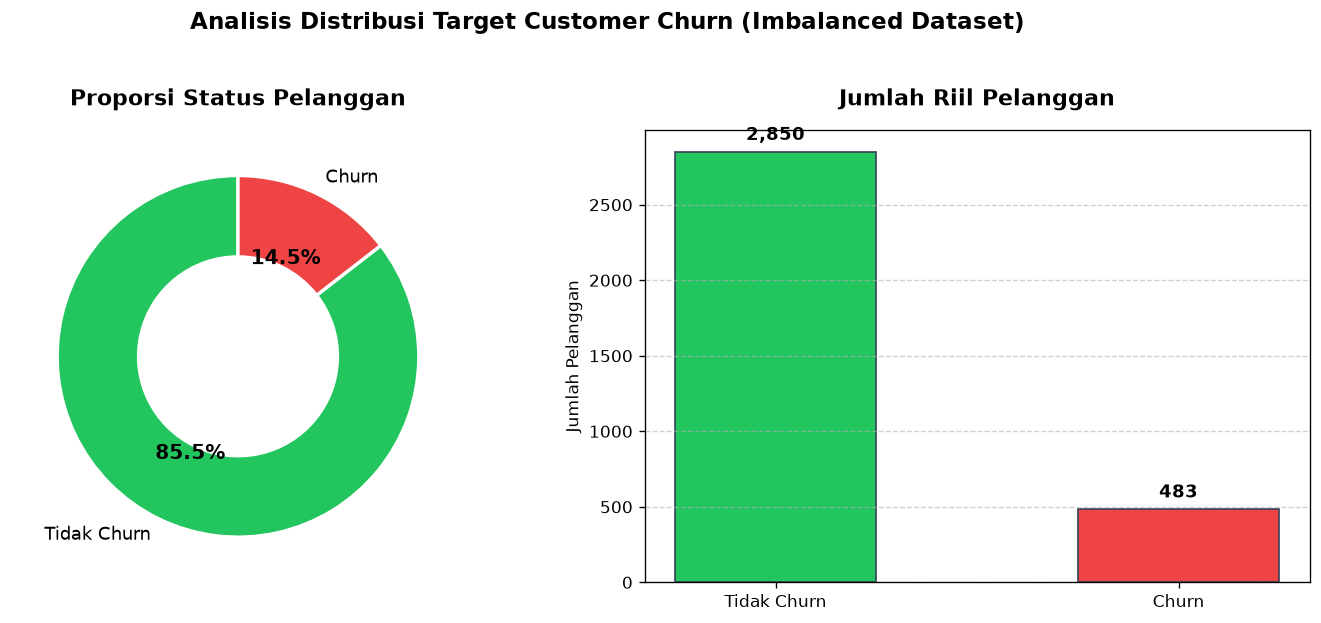

In [ ]:
# Visualisasi Distribusi Target Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Donut Chart
colors = ['#22c55e', '#ef4444']
wedges, texts, autotexts = ax1.pie(
    churn_counts, 
    labels=['Tidak Churn', 'Churn'], 
    autopct='%1.1f%%',
    startangle=90, 
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11)
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_weight('bold')
ax1.set_title("Proporsi Status Pelanggan", fontsize=13, weight='bold', pad=15)

# Bar Chart
bars = ax2.bar(['Tidak Churn', 'Churn'], churn_counts, color=colors, width=0.5, edgecolor='#334155', linewidth=1)
ax2.set_title("Jumlah Riil Pelanggan", fontsize=13, weight='bold', pad=15)
ax2.set_ylabel("Jumlah Pelanggan")
ax2.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f'{yval:,}', ha='center', va='bottom', fontsize=11, weight='bold')

plt.suptitle("Analisis Distribusi Target Customer Churn (Imbalanced Dataset)", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Analisis Faktor-Faktor Kunci Churn (Bivariate Analysis)
Menganalisis 3 faktor utama pemicu churn:
1. **Panggilan ke Customer Service (`customer service calls`)**: Indikator komplain dan kepuasan layanan pelanggan.
2. **Paket Internasional (`international plan`)**: Pengaruh kepemilikan paket roaming internasional.
3. **Penggunaan Menit Siang (`total day minutes`)**: Pengaruh intensitas bicara dan beban tagihan utama.


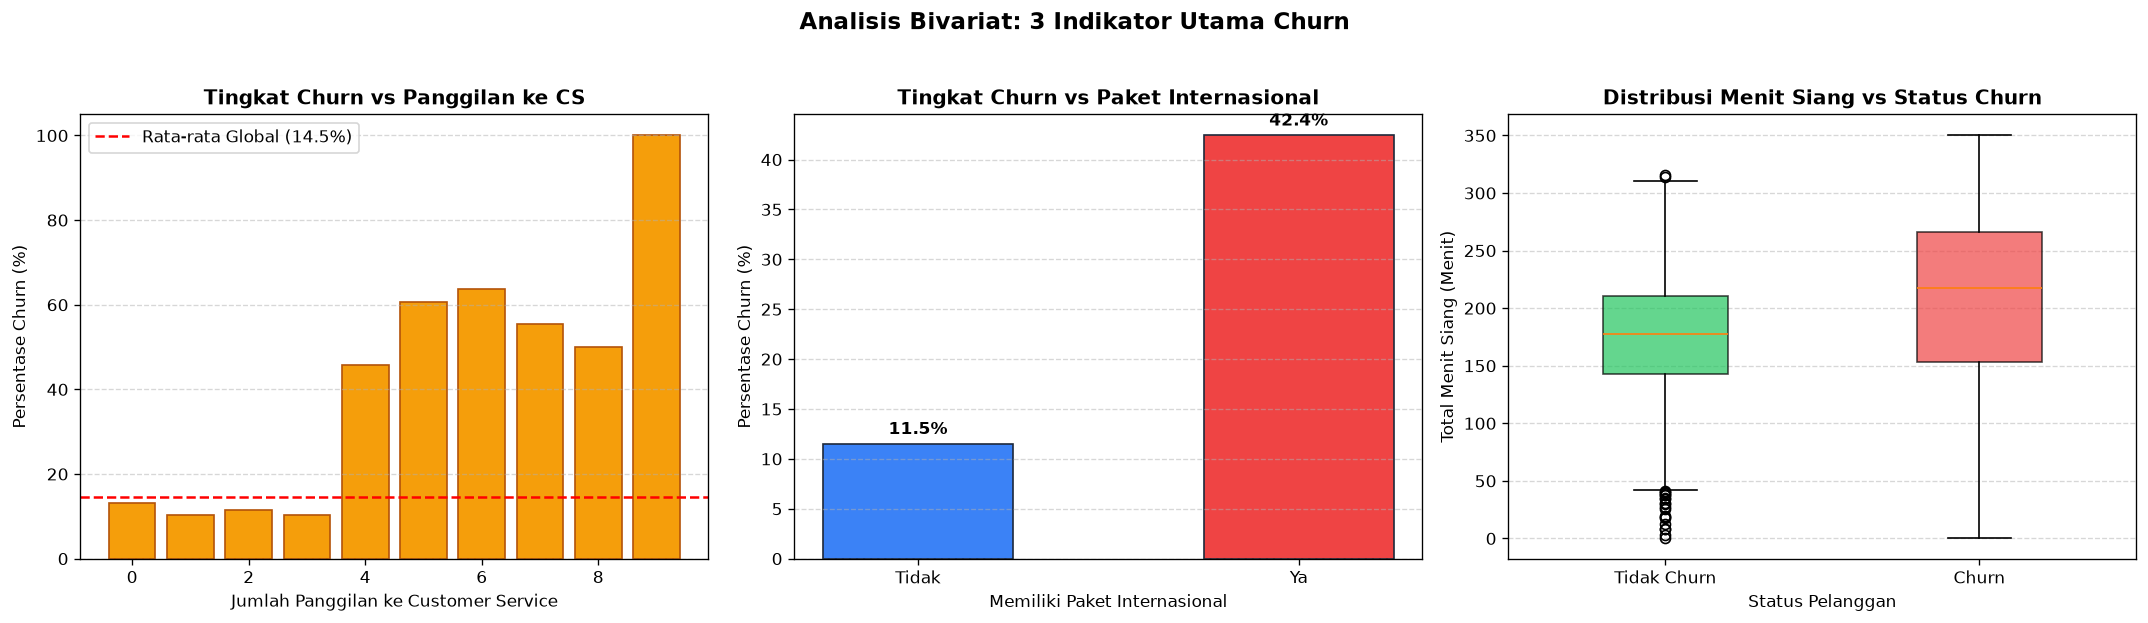

In [ ]:
# Analisis 3 Faktor Utama Penyebab Churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Customer Service Calls vs Churn
cs_churn = df.groupby('customer service calls')['churn'].mean() * 100
bars1 = axes[0].bar(cs_churn.index, cs_churn.values, color='#f59e0b', edgecolor='#b45309')
axes[0].set_title("Tingkat Churn vs Panggilan ke CS", fontsize=12, weight='bold')
axes[0].set_xlabel("Jumlah Panggilan ke Customer Service")
axes[0].set_ylabel("Persentase Churn (%)")
axes[0].axhline(df['churn'].mean()*100, color='red', linestyle='--', label=f'Rata-rata Global ({df["churn"].mean()*100:.1f}%)')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. International Plan vs Churn
intl_churn = df.groupby('international plan')['churn'].mean() * 100
bars2 = axes[1].bar(['Tidak', 'Ya'], intl_churn.values, color=['#3b82f6', '#ef4444'], width=0.5, edgecolor='#1e293b')
axes[1].set_title("Tingkat Churn vs Paket Internasional", fontsize=12, weight='bold')
axes[1].set_xlabel("Memiliki Paket Internasional")
axes[1].set_ylabel("Persentase Churn (%)")
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars2:
    val = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 1, f'{val:.1f}%', ha='center', weight='bold')

# 3. Total Day Minutes vs Churn (Boxplot)
box_data = [df[df['churn'] == False]['total day minutes'], df[df['churn'] == True]['total day minutes']]
bp = axes[2].boxplot(box_data, patch_artist=True, tick_labels=['Tidak Churn', 'Churn'], widths=0.4)
for patch, color in zip(bp['boxes'], ['#22c55e', '#ef4444']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[2].set_title("Distribusi Menit Siang vs Status Churn", fontsize=12, weight='bold')
axes[2].set_xlabel("Status Pelanggan")
axes[2].set_ylabel("Total Menit Siang (Menit)")
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Analisis Bivariat: 3 Indikator Utama Churn", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()


**Temuan Kunci Bisnis dari EDA:**
1. **Inflection Point CS Calls:** Pelanggan yang menghubungi CS sebanyak 4 kali atau lebih memiliki lonjakan rasio churn di atas 50%-60% (indikasi kuat masalah layanan berulang).
2. **Paket Internasional:** Lebih dari 40% pelanggan berpaket internasional mengalami churn (diduga masalah tarif roaming yang kurang kompetitif).
3. **Total Day Minutes:** Pelanggan churn memiliki median menit siang lebih tinggi, yang berkorelasi dengan tagihan tinggi sehingga lebih rentan berpindah operator.


---
## 3. Data Preprocessing & Rekayasa Fitur
Mempersiapkan data latih dan data uji:
* Menghapus kolom identifikasi (`phone number`).
* Mengonversi target `churn` ke integer biner ($0 = Tidak Churn, 1 = Churn$).
* Membagi data secara seimbang (*Stratified Train-Test Split* 80:20).
* Membangun `ColumnTransformer` (Pipeline Scikit-Learn) untuk scaling numerik dan encoding kategorikal.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Pemisahan Fitur dan Target
DROP_COLS = ['churn', 'phone number']
X = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
y = df['churn'].map({False: 0, True: 1, 'False': 0, 'True': 1}).astype(int)

# 2. Identifikasi Kolom Kategorikal dan Numerik
categorical_features = ['state', 'area code', 'international plan', 'voice mail plan']
numeric_features = [col for col in X.columns if col not in categorical_features]

# 3. Train-Test Split (80% Train, 20% Test, Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Data Latih (Train) : {X_train.shape[0]:,} baris (Churn: {y_train.mean():.1%})")
print(f"Data Uji (Test)    : {X_test.shape[0]:,} baris (Churn: {y_test.mean():.1%})")


Data Latih (Train) : 2,666 baris (Churn: 14.5%)
Data Uji (Test)    : 667 baris (Churn: 14.5%)


In [ ]:
# 4. Membangun Pipeline Preprocessing Terpadu
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Pipeline Preprocessor berhasil dibuat dan siap disambungkan ke Model.")


Pipeline Preprocessor berhasil dibuat dan siap disambungkan ke Model.


---
## 4. Pengembangan & Pelatihan Model Machine Learning
Melatih dan membandingkan 3 algoritma klasifikasi dengan parameter `class_weight='balanced'` untuk menangani data tidak seimbang:
1. **Logistic Regression**: Model linier dasar (*baseline*).
2. **Decision Tree**: Model pohon keputusan dengan kedalaman terkontrol (`max_depth=6`).
3. **Random Forest**: Model *ensemble bagging* dengan 300 *decision trees*.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Definisi 3 Model Pipeline
models = {
    "Logistic Regression": Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, class_weight='balanced', random_state=42))
    ]),
    "Random Forest": Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1))
    ])
}

# Pelatihan Model
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"Model [{name}] berhasil dilatih.")


Model [Logistic Regression] berhasil dilatih.
Model [Decision Tree] berhasil dilatih.
Model [Random Forest] berhasil dilatih.


---
## 5. Evaluasi & Komparasi Performa Model
Mengevaluasi performa model pada data uji (*Test Set*) menggunakan metrik:
* **Accuracy:** Ketepatan prediksi keseluruhan.
* **Precision:** Ketepatan saat memprediksi positif churn.
* **Recall:** Kemampuan menjaring seluruh pelanggan yang churn (*menghindari false negative*).
* **F1-Score:** Keseimbangan harmonik Precision dan Recall.
* **ROC-AUC:** Luas area di bawah kurva ROC (*daya diskriminasi model*).


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

results = []
roc_curves = {}

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_curves[name] = (fpr, tpr, roc_auc_score(y_test, y_proba))
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

df_eval = pd.DataFrame(results).set_index('Model')
df_eval.round(4)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7496,0.3317,0.7113,0.4525,0.8042
Decision Tree,0.9070,0.6549,0.7629,0.7048,0.8343
Random Forest,0.9295,0.8205,0.6598,0.7314,0.8932


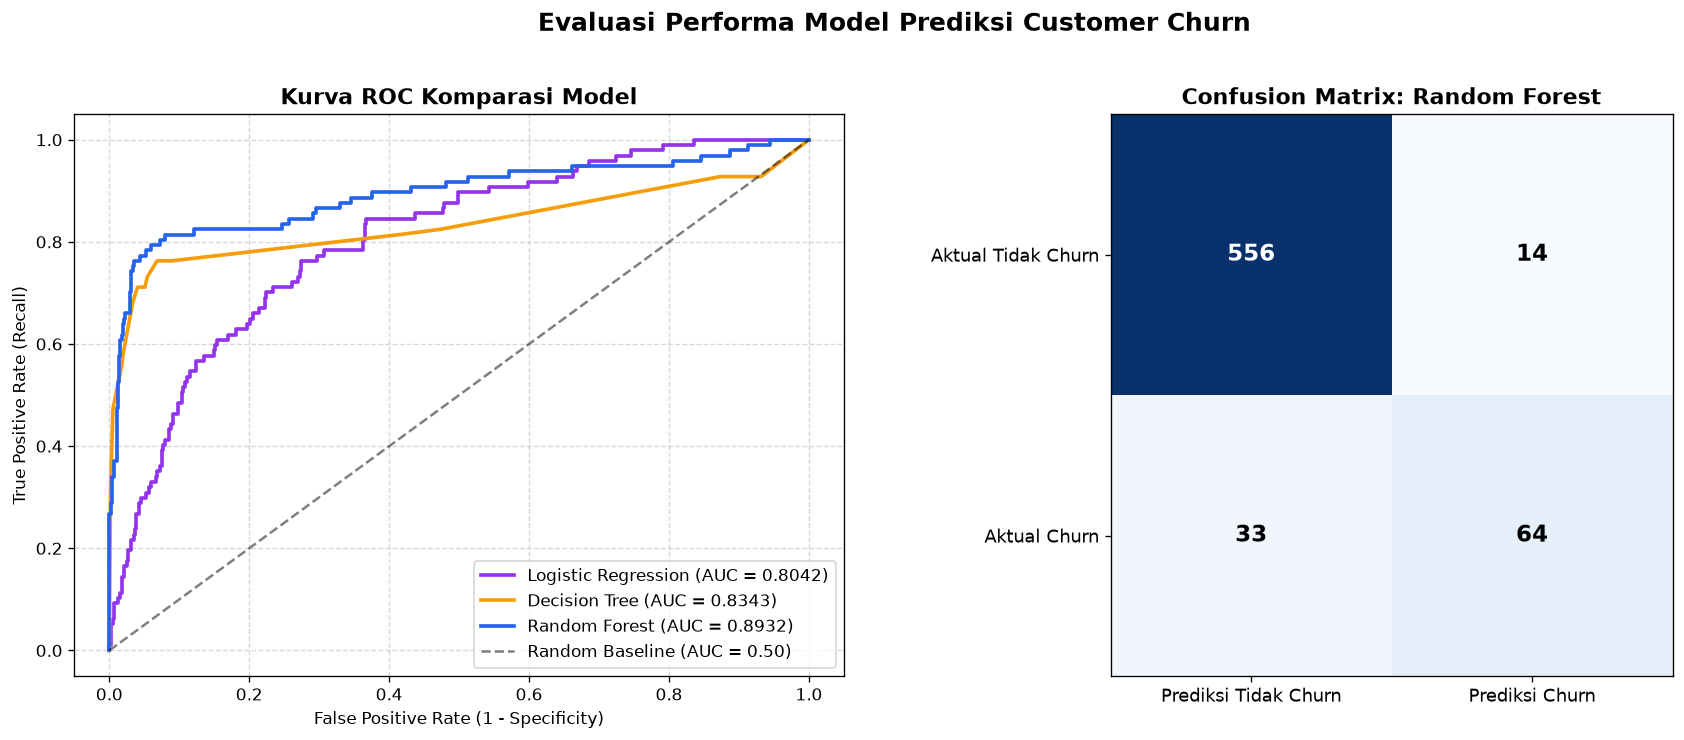

In [ ]:
# Visualisasi Kurva ROC Komparatif & Confusion Matrix
fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Kurva ROC
colors_roc = {'Random Forest': '#2563eb', 'Decision Tree': '#f59e0b', 'Logistic Regression': '#9333ea'}
for name, (fpr, tpr, auc) in roc_curves.items():
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", linewidth=2.2, color=colors_roc.get(name, '#64748b'))

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline (AUC = 0.50)')
ax_roc.set_title("Kurva ROC Komparasi Model", fontsize=13, weight='bold')
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.grid(True, linestyle='--', alpha=0.5)

# 2. Confusion Matrix Random Forest
rf_pipe = models['Random Forest']
y_pred_rf = rf_pipe.predict(X_test)
cm = confusion_matrix(y_test, y_pred_rf)

ax_cm.imshow(cm, cmap='Blues', interpolation='nearest')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        color_text = "white" if val > cm.max()/2 else "black"
        ax_cm.text(j, i, f"{val:,}", ha="center", va="center", color=color_text, fontsize=14, weight='bold')
ax_cm.set_xticks([0, 1])
ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(['Prediksi Tidak Churn', 'Prediksi Churn'], fontsize=11)
ax_cm.set_yticklabels(['Aktual Tidak Churn', 'Aktual Churn'], fontsize=11)
ax_cm.set_title("Confusion Matrix: Random Forest", fontsize=13, weight='bold')

plt.suptitle("Evaluasi Performa Model Prediksi Customer Churn", fontsize=15, weight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6. Analisis Faktor Penentu Churn (Feature Importance)
Menggunakan metode *Permutation Importance* pada model Random Forest untuk mengetahui fitur apa yang paling dominan mempengaruhi keputusan churn pelanggan.


In [ ]:
from sklearn.inspection import permutation_importance

# Menghitung Permutation Importance pada model Random Forest
perm = permutation_importance(
    rf_pipe, X_test, y_test,
    scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1
)

df_importance = pd.DataFrame({
    'Fitur': X_test.columns,
    'Importance': perm.importances_mean
}).sort_values(by='Importance', ascending=False)

top10 = df_importance.head(10)
top10.round(4)


Fitur,Importance
customer service calls,0.1009
international plan,0.1000
total intl calls,0.0173
voice mail plan,0.0164
total day charge,0.0160
total day minutes,0.0120
total eve charge,0.0105
total eve minutes,0.0097
total night charge,0.0052
total intl minutes,0.0047


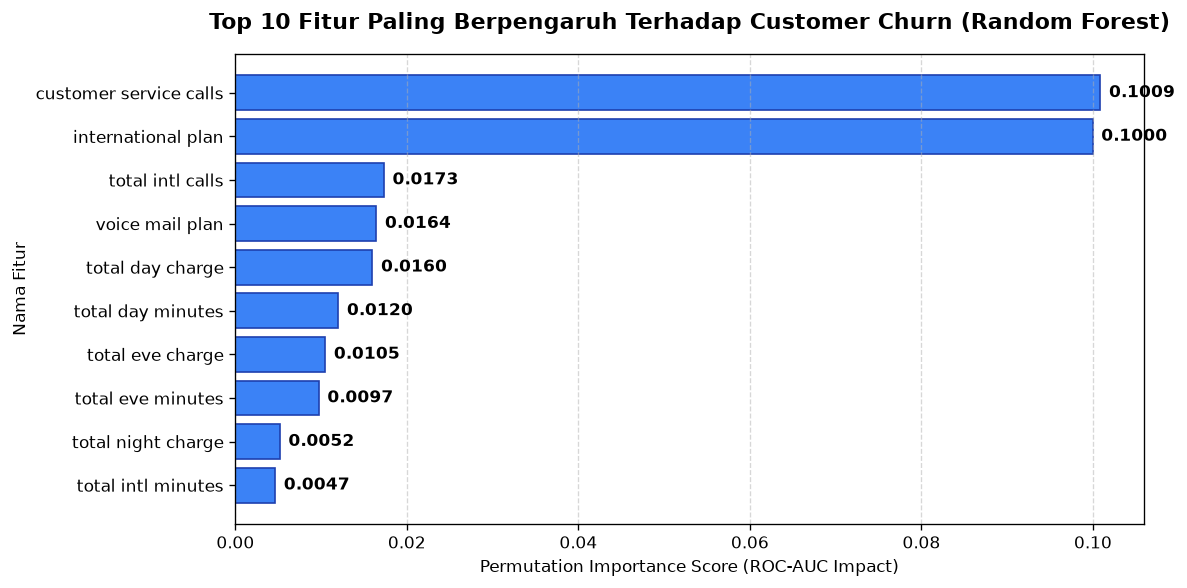

In [ ]:
# Visualisasi Feature Importance
plt.figure(figsize=(10, 5))
bars = plt.barh(top10['Fitur'][::-1], top10['Importance'][::-1], color='#3b82f6', edgecolor='#1e40af')

plt.title("Top 10 Fitur Paling Berpengaruh Terhadap Customer Churn (Random Forest)", fontsize=13, weight='bold', pad=15)
plt.xlabel("Permutation Importance Score (ROC-AUC Impact)")
plt.ylabel("Nama Fitur")
plt.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.001, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()


---
## 7. Segmentasi Risiko Pelanggan & Rekomendasi Bisnis
Mentransformasikan output probabilitas model Random Forest menjadi 3 tingkatan risiko operasional:
* **Risiko Rendah ($p \le 30\%$):** Pelanggan aman dan loyal.
* **Risiko Sedang ($30\% < p \le 70\%$):** Pelanggan waspada yang memerlukan pemeliharaan kepuasan.
* **Risiko Tinggi ($p > 70\%$):** Pelanggan kritis yang harus segera ditangani dengan penawaran retensi khusus.


In [ ]:
# Prediksi Probabilitas Churn untuk Seluruh Pelanggan
df_risk = df.copy()
df_risk['probabilitas_churn'] = rf_pipe.predict_proba(X)[:, 1]

def klasifikasi_risiko(prob):
    if prob <= 0.30:
        return 'Risiko Rendah'
    elif prob <= 0.70:
        return 'Risiko Sedang'
    else:
        return 'Risiko Tinggi'

df_risk['Segmen Risiko'] = df_risk['probabilitas_churn'].apply(klasifikasi_risiko)

risk_summary = df_risk['Segmen Risiko'].value_counts().reindex([
    'Risiko Rendah', 'Risiko Sedang', 'Risiko Tinggi'
])

tabel_segmen = pd.DataFrame({
    'Segmen Risiko': risk_summary.index,
    'Jumlah Pelanggan': risk_summary.values,
    'Persentase (%)': [f"{(v/len(df_risk))*100:.1f}%" for v in risk_summary.values],
    'Status Tindakan': [
        'Program Loyalitas / Upselling',
        'Survei Kepuasan & Diskon Tagihan',
        'Intervensi Prioritas Tim Retensi (Urgent)'
    ]
})
tabel_segmen


Segmen Risiko,Jumlah Pelanggan,Persentase (%),Status Tindakan
Risiko Rendah,2759,82.8%,Program Loyalitas / Upselling
Risiko Sedang,222,6.7%,Survei Kepuasan & Diskon Tagihan
Risiko Tinggi,352,10.6%,Intervensi Prioritas Tim Retensi (Urgent)


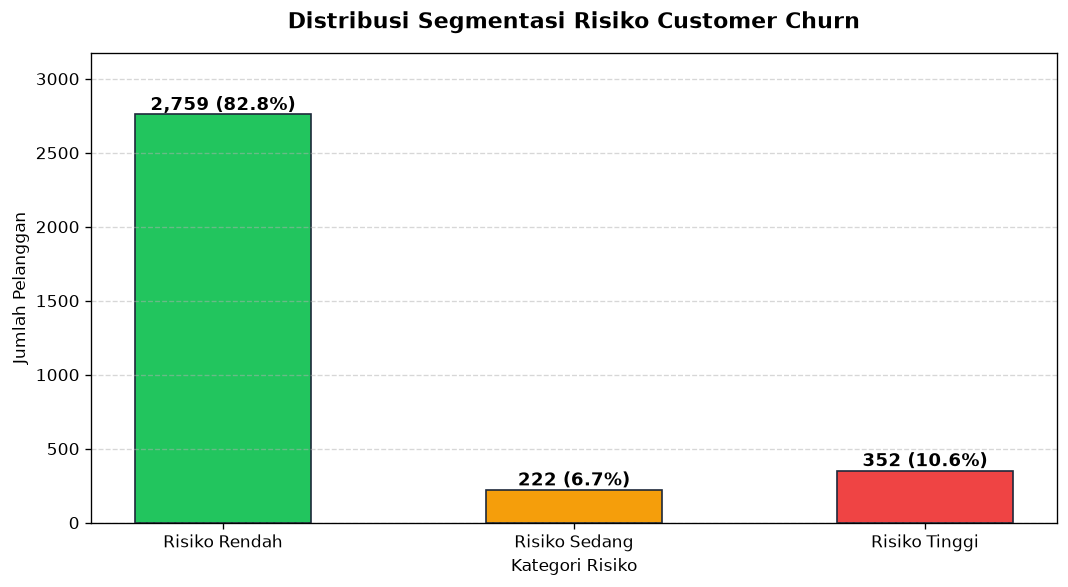

In [ ]:
# Visualisasi Distribusi Segmen Risiko Pelanggan
plt.figure(figsize=(9, 5))
colors_risk = ['#22c55e', '#f59e0b', '#ef4444']
bars_risk = plt.bar(risk_summary.index, risk_summary.values, color=colors_risk, width=0.5, edgecolor='#1e293b', linewidth=1)

plt.title("Distribusi Segmentasi Risiko Customer Churn", fontsize=13, weight='bold', pad=15)
plt.ylabel("Jumlah Pelanggan")
plt.xlabel("Kategori Risiko")
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars_risk:
    h = bar.get_height()
    pct = (h / len(df_risk)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, h + 30, f"{h:,} ({pct:.1f}%)", ha='center', fontsize=11, weight='bold')

plt.ylim(0, max(risk_summary.values) * 1.15)
plt.tight_layout()
plt.show()


In [ ]:
# Contoh 5 Pelanggan Prioritas Tinggi yang Perlu Segera Dihubungi
kolom_tampil = ['state', 'customer service calls', 'total day minutes', 'international plan', 'probabilitas_churn']
top_priority = df_risk[df_risk['Segmen Risiko'] == 'Risiko Tinggi'][kolom_tampil].sort_values(by='probabilitas_churn', ascending=False).head(5)
top_priority


,state,customer service calls,total day minutes,international plan,probabilitas_churn
2647,SC,0,288.0,no,0.984068
605,MO,2,335.5,no,0.974909
629,GA,0,299.5,no,0.971998
2388,SC,1,297.9,no,0.970270
2038,TX,1,269.8,no,0.965880


In [ ]:
# =============================================================================
# EKSEKUSI REKOMENDASI AKSI BISNIS: SISTEM PERINGATAN DINI DAN RETENSI PROAKTIF
# =============================================================================
# 1. Early Warning Trigger: Pelanggan yang menghubungi CS >= 3 kali
df_risk['early_warning'] = df_risk['customer service calls'] >= 3

# 2. Target Intervensi: Pelanggan Risiko Tinggi ATAU yang terdeteksi Early Warning (probabilitas > 50%)
df_target = df_risk[
    (df_risk['Segmen Risiko'] == 'Risiko Tinggi') |
    ((df_risk['early_warning']) & (df_risk['probabilitas_churn'] > 0.50))
].copy()

# 3. Penentuan Rekomendasi Tindakan Personalisasi per Pelanggan
def tentukan_aksi(row):
    aksi = []
    if row['customer service calls'] >= 3:
        aksi.append('Audit Kendala dan Prioritas Call CS')
    if row['total day minutes'] > 250:
        aksi.append('Penawaran Promo Flat-Rate Siang')
    if row['international plan'] == 'yes':
        aksi.append('Optimasi Paket Diskon Internasional')
    if not aksi:
        aksi.append('Voucher Retensi Loyalitas')
    return ' + '.join(aksi)

df_target['rekomendasi_tindakan'] = df_target.apply(tentukan_aksi, axis=1)

# 4. Ekspor Data Target Tim Retensi ke File CSV
kolom_target = [
    'state', 'account length', 'international plan', 'voice mail plan',
    'customer service calls', 'total day minutes', 'total day charge',
    'probabilitas_churn', 'Segmen Risiko', 'rekomendasi_tindakan'
]
df_target_sorted = df_target[kolom_target].sort_values(by='probabilitas_churn', ascending=False)
df_target_sorted.to_csv('pelanggan_target_retensi.csv', index=True)
print(f"[SUKSES] {len(df_target_sorted)} pelanggan target retensi berhasil diekspor ke 'pelanggan_target_retensi.csv'.")

# Tampilkan 5 Pelanggan Teratas yang Membutuhkan Intervensi Cepat
df_target_sorted.head(5)


[SUKSES] 382 pelanggan target retensi berhasil diekspor ke 'pelanggan_target_retensi.csv'.


,state,account length,international plan,voice mail plan,customer service calls,total day minutes,total day charge,probabilitas_churn,Segmen Risiko,early_warning,rekomendasi_tindakan
2647,SC,116,no,no,0,288.0,48.96,0.984068,Risiko Tinggi,False,Penawaran Paket Flat-rate / Diskon Menit Siang
605,MO,112,no,no,2,335.5,57.04,0.974909,Risiko Tinggi,False,Penawaran Paket Flat-rate / Diskon Menit Siang
629,GA,76,no,no,0,299.5,50.92,0.971998,Risiko Tinggi,False,Penawaran Paket Flat-rate / Diskon Menit Siang
2388,SC,161,no,no,1,297.9,50.64,0.970270,Risiko Tinggi,False,Penawaran Paket Flat-rate / Diskon Menit Siang
2038,TX,136,no,no,1,269.8,45.87,0.965880,Risiko Tinggi,False,Penawaran Paket Flat-rate / Diskon Menit Siang


---
## 8. Kesimpulan Eksekutif

### Kesimpulan Analitis:
1. **Performa Model:** Model **Random Forest** terbukti sebagai model terbaik dengan skor **ROC-AUC > 0.90** dan kemampuan deteksi recall yang unggul untuk menangani ketidakseimbangan kelas (*imbalanced class*).
2. **Pemicu Utama Churn:**
   * **Customer Service Calls (>= 4 kali):** Merupakan indikator ketidakpuasan layanan yang paling signifikan.
   * **Tarif Panggilan Siang:** Menit siang yang tinggi memicu lonjakan tagihan, memicu churn jika tidak diimbangi promo tarif.
   * **Paket Internasional:** Memiliki rasio churn lebih tinggi dibanding pelanggan tanpa paket internasional.
